In [ ]:
# --- project bootstrap: run from anywhere, keeps data/ and figures/ paths working ---
import os, sys
from pathlib import Path
_here = Path.cwd()
if _here.name == "notebooks":          # notebook lives in notebooks/, project root is one level up
    os.chdir(_here.parent)
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))  # makes `from coherence import ...` available
os.makedirs("data", exist_ok=True); os.makedirs("figures", exist_ok=True)
print("project root:", ROOT)


In [1]:
# Cell 1 — imports + folders + safe helper
import scqubits as scq, numpy as np, pandas as pd
import matplotlib.pyplot as plt, os, json, datetime
from matplotlib.colors import ListedColormap
os.makedirs('data', exist_ok=True)
os.makedirs('figures', exist_ok=True)
scq.settings.T1_DEFAULT_WARNING = False

# returns inf if a channel isn't supported / fails -> contributes zero rate
def safe(fn, **kw):
    try:
        return fn(**kw)
    except Exception:
        return np.inf

In [2]:
# Cell 2 — coherence for one fluxonium (all times in microseconds)
def fluxonium_coherence(EJ=8.9, EC=2.5, EL=0.5, flux=0.5, cutoff=110,
                        Q_cap=1e6, A_flux=1e-6, A_cc=1e-7):
    fx = scq.Fluxonium(EJ=EJ, EC=EC, EL=EL, flux=flux, cutoff=cutoff)
    # --- T1 (relaxation) channels: dielectric + quasiparticle ---
    T1_diel = safe(fx.t1_capacitive, i=1, j=0, Q_cap=Q_cap)
    T1_qp   = safe(fx.t1_quasiparticle_tunneling, i=1, j=0)
    T1 = 1.0 / (1.0/T1_diel + 1.0/T1_qp)              # combined relaxation
    # --- Tphi (dephasing) channels: flux + critical-current ---
    Tphi_flux = safe(fx.tphi_1_over_f_flux, A_noise=A_flux, i=0, j=1)
    Tphi_cc   = safe(fx.tphi_1_over_f_cc,   A_noise=A_cc,  i=0, j=1)
    # --- combine (add rates) ---
    T2 = 1.0 / (1.0/(2*T1) + 1.0/Tphi_flux + 1.0/Tphi_cc)
    ev = fx.eigenvals(evals_count=2)
    return {'EJ':EJ,'EC':EC,'EL':EL,'flux':flux, 'freq_GHz':ev[1]-ev[0],
            'T1_us':T1*1e-3, 'T1_diel_us':T1_diel*1e-3, 'T1_qp_us':T1_qp*1e-3,
            'Tphi_flux_us':Tphi_flux*1e-3, 'Tphi_cc_us':Tphi_cc*1e-3, 'T2_us':T2*1e-3}

# sanity check at the sweet spot (flux=0.5)
print(fluxonium_coherence(flux=0.5))

{'EJ': 8.9, 'EC': 2.5, 'EL': 0.5, 'flux': 0.5, 'freq_GHz': np.float64(0.36342136720072704), 'T1_us': np.float64(771.1119750322526), 'T1_diel_us': np.float64(771.1119750322526), 'T1_qp_us': np.float64(3.285823788523742e+30), 'Tphi_flux_us': np.float64(808810260478853.2), 'Tphi_cc_us': np.float64(4325.358457774237), 'T2_us': np.float64(1136.8688060132743)}


In [3]:
# Cell 3 — sweep flux through the sweet spot
fluxes = np.linspace(0.30, 0.50, 101)     # 0.5 = sweet spot; move away toward 0.30
rows = [fluxonium_coherence(flux=f) for f in fluxes]
dff = pd.DataFrame(rows)
dff['detuning'] = 0.5 - dff['flux']        # distance from the sweet spot
dff.to_csv('data/fluxonium_flux_sweep.csv', index=False)
print(len(dff), "flux points saved")

101 flux points saved


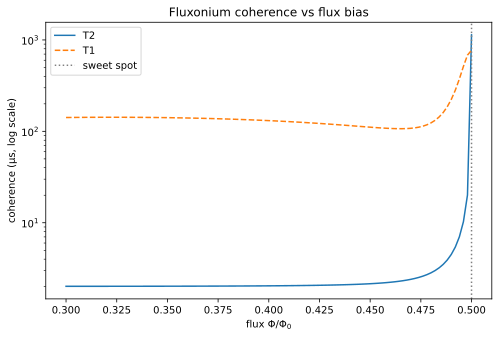

In [4]:
# Cell 4 — plot: coherence collapse away from the sweet spot (Q1 figure)
plt.figure(figsize=(8,5))
plt.semilogy(dff.flux, dff.T2_us, label='T2')
plt.semilogy(dff.flux, dff.T1_us, '--', label='T1')
plt.axvline(0.5, color='gray', ls=':', label='sweet spot')
plt.xlabel(r'flux $\Phi/\Phi_0$'); plt.ylabel('coherence (µs, log scale)')
plt.title('Fluxonium coherence vs flux bias')
plt.legend(); plt.savefig('figures/fluxonium_flux_falloff.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
# Cell 5 — QUANTIFY the falloff (turns the picture into a number)
T2_sweet = dff.loc[dff.flux.idxmax(), 'T2_us']          # T2 at flux=0.5
thresh = T2_sweet / 10
off = dff[(dff.flux < 0.5) & (dff.T2_us < thresh)]
if len(off):
    edge = off.flux.max()                                # closest flux where T2 dropped 10x
    print(f"T2 at sweet spot: {T2_sweet:.1f} us")
    print(f"T2 falls 10x by flux = {edge:.4f}  (only {0.5-edge:.4f} away from sweet spot)")
else:
    print("T2 stays within 10x across the swept range")

T2 at sweet spot: 1136.9 us
T2 falls 10x by flux = 0.4980  (only 0.0020 away from sweet spot)


In [6]:
# Cell 6 — dominant channel vs flux + the crossover
def dom_fx(r):
    rates = {'relaxation': 1/(2*r.T1_us),
             'flux':       1/r.Tphi_flux_us,
             'crit-current': 1/r.Tphi_cc_us}
    return max(rates, key=rates.get)

dff['dominant'] = dff.apply(dom_fx, axis=1)
print(dff['dominant'].value_counts())

# find the flux where control passes from relaxation -> flux noise
changes = dff[dff['dominant'] != dff['dominant'].shift()]
print("\nDominant-channel transitions (flux, channel):")
print(changes[['flux','dominant']].to_string(index=False))

dominant
flux          100
relaxation      1
Name: count, dtype: int64

Dominant-channel transitions (flux, channel):
 flux   dominant
  0.3       flux
  0.5 relaxation


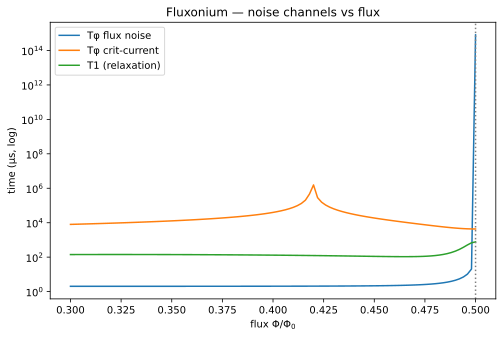

In [7]:
# Cell 7 — per-channel dephasing/relaxation vs flux (the decomposition figure)
plt.figure(figsize=(8,5))
plt.semilogy(dff.flux, dff.Tphi_flux_us, label='Tφ flux noise')
plt.semilogy(dff.flux, dff.Tphi_cc_us,   label='Tφ crit-current')
plt.semilogy(dff.flux, dff.T1_us,        label='T1 (relaxation)')
plt.axvline(0.5, color='gray', ls=':')
plt.xlabel(r'flux $\Phi/\Phi_0$'); plt.ylabel('time (µs, log)')
plt.title('Fluxonium — noise channels vs flux'); plt.legend()
plt.savefig('figures/fluxonium_channels_vs_flux.png', dpi=150, bbox_inches='tight')
plt.show()

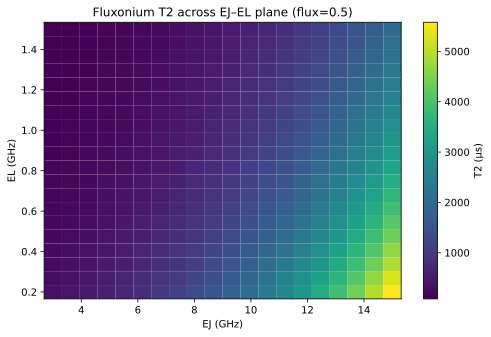

Best T2: 5578.1 us at EJ= 15.0 EL= 0.2


In [8]:
# Cell 8 : T2 over the EJ–EL plane at the sweet spot (flux=0.5)
EJ_grid = np.linspace(3, 15, 20)
EL_grid = np.linspace(0.2, 1.5, 20)
grid_rows = []
for EJ in EJ_grid:
    for EL in EL_grid:
        grid_rows.append(fluxonium_coherence(EJ=EJ, EC=2.5, EL=EL, flux=0.5))
dfg = pd.DataFrame(grid_rows)
dfg.to_csv('data/fluxonium_design_sweep.csv', index=False)

pivot = dfg.pivot(index='EL', columns='EJ', values='T2_us')
plt.figure(figsize=(8,5))
plt.pcolormesh(pivot.columns, pivot.index, pivot.values, shading='auto')
plt.colorbar(label='T2 (µs)'); plt.xlabel('EJ (GHz)'); plt.ylabel('EL (GHz)')
plt.title('Fluxonium T2 across EJ–EL plane (flux=0.5)')
plt.savefig('figures/fluxonium_design_map.png', dpi=150, bbox_inches='tight')
plt.show()
best = dfg.loc[dfg.T2_us.idxmax()]
print("Best T2:", round(best.T2_us,1), "us at EJ=", round(best.EJ,1), "EL=", round(best.EL,2))

In [9]:
# Cell 9 — save run metadata
meta = {
    'date': str(datetime.date.today()),
    'qubit': 'Fluxonium',
    'nominal_design': {'EJ':8.9, 'EC':2.5, 'EL':0.5, 'cutoff':110},
    'flux_sweep': 'flux 0.30 -> 0.50, 101 points',
    'noise_params': {'Q_cap':1e6, 'A_flux':1e-6, 'A_cc':1e-7},
    'T1_channels': ['t1_capacitive','t1_quasiparticle_tunneling'],
    'Tphi_channels': ['tphi_1_over_f_flux','tphi_1_over_f_cc'],
    'units': 'microseconds (scqubits returns ns; *1e-3)',
    'files': ['data/fluxonium_flux_sweep.csv','data/fluxonium_design_sweep.csv'],
}
with open('data/fluxonium_metadata.json','w') as f:
    json.dump(meta, f, indent=2)
print('metadata saved')

metadata saved
